# HouseLens model training and testing

This notebook follows the sample submission: inspect the data, prepare inputs, split into training and test groups, compare models, and review results. The data is historical house sales in Ames, Iowa, USA. Prices are in US dollars.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from train_model import build_preprocessor, FEATURES

pd.set_option('display.max_columns', 20)

## 1. Load and inspect the training data

The target column is `SalePrice`. The Kaggle competition test file has no target values, so it cannot be used to calculate model accuracy.

In [2]:
data = pd.read_csv('data/train.csv')
print('Rows and columns:', data.shape)
print('Sale price range:', data['SalePrice'].min(), 'to', data['SalePrice'].max(), 'USD')
display(data[['OverallQual', 'GrLivArea', 'Neighborhood', 'SalePrice']].head())
print('Missing values in selected features:')
display(data[FEATURES].isnull().sum().to_frame('Missing values'))

Rows and columns: (1460, 81)
Sale price range: 34900 to 755000 USD


,OverallQual,GrLivArea,Neighborhood,SalePrice
0,7,1710,CollgCr,208500
1,6,1262,Veenker,181500
2,7,1786,CollgCr,223500
3,7,1717,Crawfor,140000
4,8,2198,NoRidge,250000


Missing values in selected features:


,Missing values
OverallQual,0
GrLivArea,0
GarageCars,0
TotalBsmtSF,0
FullBath,0
YearBuilt,0
LotArea,0
Neighborhood,0


## 2. Prepare features and make a holdout split

Eighty percent is used to fit the comparison models. The remaining 20% is kept aside to check predictions on rows those models did not train on. A fixed random seed makes the split repeatable.

In [3]:
X = data[FEATURES]
y = data['SalePrice']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training rows:', len(X_train))
print('Holdout rows:', len(X_test))

Training rows: 1168
Holdout rows: 292


## 3. Train and compare three models

The median baseline gives context: a machine-learning model should do better than always predicting a typical price. The preprocessing fills missing values and converts neighborhood names into columns.

In [4]:
models = {
    'Median price baseline': Pipeline([
        ('prepare', build_preprocessor()),
        ('model', DummyRegressor(strategy='median'))
    ]),
    'Linear regression': Pipeline([
        ('prepare', build_preprocessor(scale=True)),
        ('model', LinearRegression())
    ]),
    'Random forest': Pipeline([
        ('prepare', build_preprocessor()),
        ('model', RandomForestRegressor(
            n_estimators=150, max_depth=12, min_samples_leaf=2,
            random_state=42, n_jobs=-1
        ))
    ])
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    results.append({
        'Model': name,
        'MAE (USD)': mean_absolute_error(y_test, predicted),
        'RMSE (USD)': np.sqrt(mean_squared_error(y_test, predicted)),
        'R2': r2_score(y_test, predicted)
    })

results = pd.DataFrame(results).sort_values('MAE (USD)')
display(results.round(2))
best_name = results.iloc[0]['Model']
print('Best by holdout MAE:', best_name)

,Model,MAE (USD),RMSE (USD),R2
2,Random forest,18529.55,29695.05,0.89
1,Linear regression,21842.99,36228.29,0.83
0,Median price baseline,59568.25,88667.17,-0.02


Best by holdout MAE: Random forest


## 4. Compare errors visually

MAE is the average absolute difference between a predicted and actual price. A lower value is better.

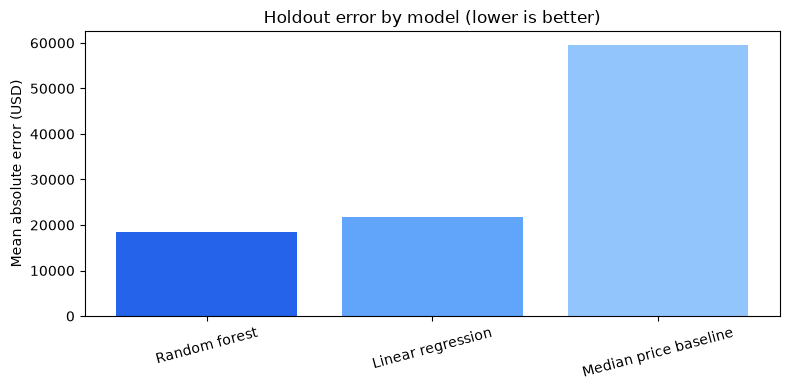

In [5]:
plt.figure(figsize=(8, 4))
plt.bar(
    results['Model'], results['MAE (USD)'],
    color=['#2563eb', '#60a5fa', '#93c5fd']
)
plt.ylabel('Mean absolute error (USD)')
plt.title('Holdout error by model (lower is better)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 5. Review some random forest predictions

The error for one house can be much higher or lower than the overall MAE. The MAE is only an average for this holdout sample.

In [6]:
forest = models['Random forest']
example_predictions = pd.DataFrame({
    'Actual sale price': y_test.iloc[:10].values,
    'Predicted price': forest.predict(X_test.iloc[:10])
})
example_predictions['Absolute error'] = (
    example_predictions['Actual sale price'] -
    example_predictions['Predicted price']
).abs()
display(example_predictions.round(0))

,Actual sale price,Predicted price,Absolute error
0,154500,137674.0,16826.0
1,325000,331985.0,6985.0
2,115000,116648.0,1648.0
3,159000,154185.0,4815.0
4,315500,311278.0,4222.0
5,75500,79282.0,3782.0
6,311500,207733.0,103767.0
7,146000,152431.0,6431.0
8,84500,78434.0,6066.0
9,135500,133113.0,2387.0


## 6. Use the separate Kaggle test file

The labeled training set is used for the holdout evaluation above. Kaggle's separate test file has no actual `SalePrice`, so its predictions are saved for later use but cannot be scored here. The HouseLens website model is refit on all labeled rows by `train_model.py`.

## Conclusion

On this fixed holdout split, the selected model can estimate Ames sale prices more closely on average than the median baseline. The data is historical and from one US city. This project does not establish performance in the Netherlands, today's market, or for unusual homes. The estimate is decision support, not financial advice.

In [7]:
competition_test = pd.read_csv('data/test.csv')
print('Unlabeled Kaggle test rows:', len(competition_test))
test_predictions = pd.read_csv('reports/test_predictions.csv')
display(test_predictions.head())

Unlabeled Kaggle test rows: 1459


,Id,SalePrice
0,1461,127049.435198
1,1462,155121.987136
2,1463,173110.022887
3,1464,180406.545595
4,1465,202440.764648
